# Predicción de defectos en producción

## Implementación de algoritmos de Machine Learning Supervisado

### Caso de estudio: Empresa manufacturera XYZ Inc.

El objetivo de este ejercicio es implementar y comparar diferentes algoritmos
de clasificación para predecir si un lote de producción será defectuoso o no
defectuoso a partir de las condiciones del proceso productivo.

In [6]:
# ============================================================
# IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Modelos de clasificación
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# División de datos y validación
from sklearn.model_selection import train_test_split, cross_val_score

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 1. Creación del conjunto de datos

Se utiliza un dataset simulado que contiene información relacionada con las
condiciones de funcionamiento de la maquinaria.

La variable objetivo es `defectuoso`:

- **0:** lote no defectuoso.
- **1:** lote defectuoso.

In [7]:
# ============================================================
# 1. CREACIÓN DEL DATASET
# ============================================================

data = {
    "temperatura": [
        70, 72, 75, 80, 85, 90, 95, 100, 78, 82,
        88, 92, 97, 76, 73, 89, 94, 99, 81, 86
    ],

    "presion": [
        30, 32, 34, 36, 40, 42, 45, 48, 35, 37,
        41, 43, 46, 33, 31, 42, 44, 47, 36, 39
    ],

    "velocidad": [
        120, 118, 115, 110, 105, 100, 95, 90, 112, 108,
        102, 98, 93, 116, 119, 101, 96, 91, 109, 104
    ],

    "horas_operacion": [
        2, 3, 4, 6, 8, 10, 12, 14, 5, 7,
        9, 11, 13, 4, 3, 10, 12, 15, 6, 8
    ],

    "vibracion": [
        1.2, 1.4, 1.6, 2.0, 2.5, 3.0, 3.5, 4.0, 1.8, 2.2,
        2.8, 3.2, 3.7, 1.5, 1.3, 3.1, 3.6, 4.2, 2.1, 2.6
    ],

    "defectuoso": [
        0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
        1, 1, 1, 0, 0, 1, 1, 1, 0, 1
    ]
}

df = pd.DataFrame(data)

df

,temperatura,presion,velocidad,horas_operacion,vibracion,defectuoso
0,70,30,120,2,1.2,0
1,72,32,118,3,1.4,0
2,75,34,115,4,1.6,0
3,80,36,110,6,2.0,0
4,85,40,105,8,2.5,1
5,90,42,100,10,3.0,1
6,95,45,95,12,3.5,1
7,100,48,90,14,4.0,1
8,78,35,112,5,1.8,0
9,82,37,108,7,2.2,0


## 2. Creación del conjunto de datos

Se crea el conjunto de datos correspondiente al caso de estudio de
predicción de lotes defectuosos en producción.

In [8]:
data = {
    "temperatura": [
        70, 72, 75, 80, 85, 90, 95, 100, 78, 82,
        88, 92, 97, 76, 73, 89, 94, 99, 81, 86
    ],
    "presion": [
        30, 32, 34, 36, 40, 42, 45, 48, 35, 37,
        41, 43, 46, 33, 31, 42, 44, 47, 36, 39
    ],
    "velocidad": [
        120, 118, 115, 110, 105, 100, 95, 90, 112, 108,
        102, 98, 93, 116, 119, 101, 96, 91, 109, 104
    ],
    "horas_operacion": [
        2, 3, 4, 6, 8, 10, 12, 14, 5, 7,
        9, 11, 13, 4, 3, 10, 12, 15, 6, 8
    ],
    "vibracion": [
        1.2, 1.4, 1.6, 2.0, 2.5, 3.0, 3.5, 4.0, 1.8, 2.2,
        2.8, 3.2, 3.7, 1.5, 1.3, 3.1, 3.6, 4.2, 2.1, 2.6
    ],
    "defectuoso": [
        0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
        1, 1, 1, 0, 0, 1, 1, 1, 0, 1
    ]
}

df = pd.DataFrame(data)

print("Dataset inicial:")
print(df)

Dataset inicial:
    temperatura  presion  velocidad  horas_operacion  vibracion  defectuoso
0            70       30        120                2        1.2           0
1            72       32        118                3        1.4           0
2            75       34        115                4        1.6           0
3            80       36        110                6        2.0           0
4            85       40        105                8        2.5           1
5            90       42        100               10        3.0           1
6            95       45         95               12        3.5           1
7           100       48         90               14        4.0           1
8            78       35        112                5        1.8           0
9            82       37        108                7        2.2           0
10           88       41        102                9        2.8           1
11           92       43         98               11        3.2        

## 3. Exploración inicial de los datos

Se realiza una exploración inicial para conocer la estructura del
dataset, sus dimensiones y la distribución de la variable objetivo.

In [9]:
print("Dimensiones del dataset:")
print(df.shape)

print("\nInformación del dataset:")
print(df.info())

print("\nEstadísticas descriptivas:")
display(df.describe())

print("\nCantidad de lotes por clase:")
print(df["defectuoso"].value_counts())

Dimensiones del dataset:
(20, 6)

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   temperatura      20 non-null     int64  
 1   presion          20 non-null     int64  
 2   velocidad        20 non-null     int64  
 3   horas_operacion  20 non-null     int64  
 4   vibracion        20 non-null     float64
 5   defectuoso       20 non-null     int64  
dtypes: float64(1), int64(5)
memory usage: 1.1 KB
None

Estadísticas descriptivas:


,temperatura,presion,velocidad,horas_operacion,vibracion,defectuoso
count,20.0000,20.000000,20.000000,20.000000,20.00000,20.000000
mean,85.1000,39.050000,105.100000,8.100000,2.56500,0.550000
std,9.3578,5.558067,9.613039,3.945684,0.94717,0.510418
min,70.0000,30.000000,90.000000,2.000000,1.20000,0.000000
25%,77.5000,34.750000,97.500000,4.750000,1.75000,0.000000
50%,85.5000,39.500000,104.500000,8.000000,2.55000,1.000000
75%,92.5000,43.250000,112.750000,11.250000,3.27500,1.000000
max,100.0000,48.000000,120.000000,15.000000,4.20000,1.000000



Cantidad de lotes por clase:
defectuoso
1    11
0     9
Name: count, dtype: int64


## 4. Distribución de la variable objetivo

Se representa gráficamente la cantidad de lotes pertenecientes a cada
una de las clases de la variable objetivo.

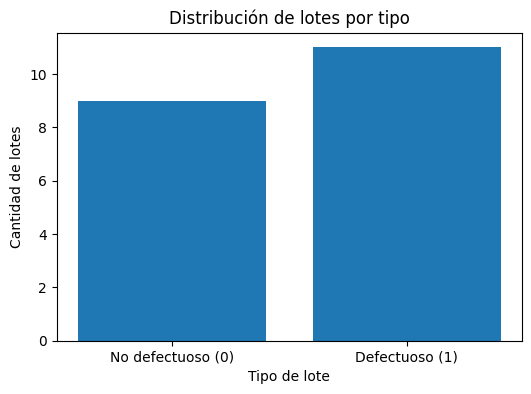

In [10]:
conteo = df["defectuoso"].value_counts().sort_index()

plt.figure(figsize=(6,4))
plt.bar(["No defectuoso (0)", "Defectuoso (1)"], conteo.values)
plt.title("Distribución de lotes por tipo")
plt.xlabel("Tipo de lote")
plt.ylabel("Cantidad de lotes")
plt.show()

## 5. Definición de variables predictoras y variable objetivo

Se separan las variables utilizadas para realizar las predicciones
de la variable que se desea predecir.

In [11]:
# Variables predictoras
X = df[[
    "temperatura",
    "presion",
    "velocidad",
    "horas_operacion",
    "vibracion"
]]

# Variable objetivo
y = df["defectuoso"]

print("Variables predictoras (X):")
display(X.head())

print("\nVariable objetivo (y):")
display(y.head())

Variables predictoras (X):


,temperatura,presion,velocidad,horas_operacion,vibracion
0,70,30,120,2,1.2
1,72,32,118,3,1.4
2,75,34,115,4,1.6
3,80,36,110,6,2.0
4,85,40,105,8,2.5



Variable objetivo (y):


,defectuoso
0,0
1,0
2,0
3,0
4,1


En Machine Learning, X representa las variables predictoras.

## 6. División de los datos en entrenamiento y prueba

El conjunto de datos se divide en dos partes: un conjunto de
entrenamiento y un conjunto de prueba.

El 70 % de los datos será utilizado para entrenar los modelos,
mientras que el 30 % restante será utilizado para evaluar su
desempeño.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)
print("Tamaño de y_train:", y_train.shape)
print("Tamaño de y_test:", y_test.shape)

Tamaño de X_train: (14, 5)
Tamaño de X_test: (6, 5)
Tamaño de y_train: (14,)
Tamaño de y_test: (6,)


## 7. Definición de los modelos de clasificación

En esta etapa se definen los algoritmos de Machine Learning
Supervisado que serán utilizados para predecir si un lote de
producción es defectuoso o no.

Se implementarán seis modelos:

1. Regresión Logística
2. Árbol de Decisión
3. Random Forest
4. K-Nearest Neighbors (KNN)
5. Support Vector Machine (SVM)
6. Naive Bayes

In [13]:
modelos = {
    "Regresión Logística": LogisticRegression(max_iter=1000),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "SVM": SVC(kernel="linear"),
    "Naive Bayes": GaussianNB()
}

print("Modelos definidos:")
for nombre in modelos:
    print("-", nombre)

Modelos definidos:
- Regresión Logística
- Árbol de Decisión
- Random Forest
- KNN
- SVM
- Naive Bayes


El diccionario modelos permite almacenar los seis clasificadores para posteriormente recorrerlos mediante un ciclo y entrenarlos bajo el mismo procedimiento.
Los parámetros utilizados corresponden al código fuente proporcionado:
- Regresión Logística: max_iter=1000
- Random Forest: n_estimators=100
- KNN: n_neighbors=3
- SVM: kernel="linear"
- Árbol de Decisión: random_state=42
- Random Forest: random_state=42

## 8. Entrenamiento de los modelos

Cada algoritmo será entrenado utilizando el conjunto de datos de
entrenamiento. Posteriormente, el modelo realizará predicciones
sobre el conjunto de prueba.

In [14]:
resultados = []

for nombre, modelo in modelos.items():

    # Entrenamiento
    modelo.fit(X_train, y_train)

    # Predicciones
    y_pred = modelo.predict(X_test)

    print("=" * 60)
    print("MODELO:", nombre)
    print("=" * 60)

    print("Predicciones:", y_pred)
    print()

MODELO: Regresión Logística
Predicciones: [0 1 0 1 1 0]

MODELO: Árbol de Decisión
Predicciones: [0 1 0 1 1 0]

MODELO: Random Forest
Predicciones: [0 1 0 1 1 0]

MODELO: KNN
Predicciones: [0 1 0 1 1 0]

MODELO: SVM
Predicciones: [0 1 0 1 1 0]

MODELO: Naive Bayes
Predicciones: [0 1 0 1 1 0]



## 9. Evaluación de los modelos

Los modelos serán evaluados utilizando Accuracy, Precision, Recall
y F1-score. Estas métricas permiten analizar diferentes aspectos
del desempeño de los clasificadores.

In [15]:
resultados = []

for nombre, modelo in modelos.items():

    # Entrenamiento
    modelo.fit(X_train, y_train)

    # Predicción
    y_pred = modelo.predict(X_test)

    # Métricas
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    # Validación cruzada
    cv_scores = cross_val_score(
        modelo,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    cv_promedio = cv_scores.mean()

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Validación cruzada": cv_promedio
    })

    print("=" * 70)
    print("MODELO:", nombre)
    print("=" * 70)

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-score:", f1)

    print("\nMatriz de confusión:")
    print(confusion_matrix(y_test, y_pred))

    print("\nReporte de clasificación:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

    print("Validación cruzada:", cv_scores)
    print("Promedio validación cruzada:", cv_promedio)

MODELO: Regresión Logística
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Matriz de confusión:
[[3 0]
 [0 3]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

Validación cruzada: [1. 1. 1. 1. 1.]
Promedio validación cruzada: 1.0
MODELO: Árbol de Decisión
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Matriz de confusión:
[[3 0]
 [0 3]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      

## 10. Comparación de los resultados

Una vez entrenados y evaluados los seis modelos, se construye una
tabla comparativa con las principales métricas obtenidas.

In [16]:
df_resultados = pd.DataFrame(resultados)

# Ordenar los modelos de acuerdo con el F1-score
df_resultados = df_resultados.sort_values(
    by="F1-score",
    ascending=False
)

display(df_resultados)

,Modelo,Accuracy,Precision,Recall,F1-score,Validación cruzada
0,Regresión Logística,1.0,1.0,1.0,1.0,1.0
1,Árbol de Decisión,1.0,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0,1.0
3,KNN,1.0,1.0,1.0,1.0,1.0
4,SVM,1.0,1.0,1.0,1.0,1.0
5,Naive Bayes,1.0,1.0,1.0,1.0,1.0


## 11. Comparación gráfica de las métricas

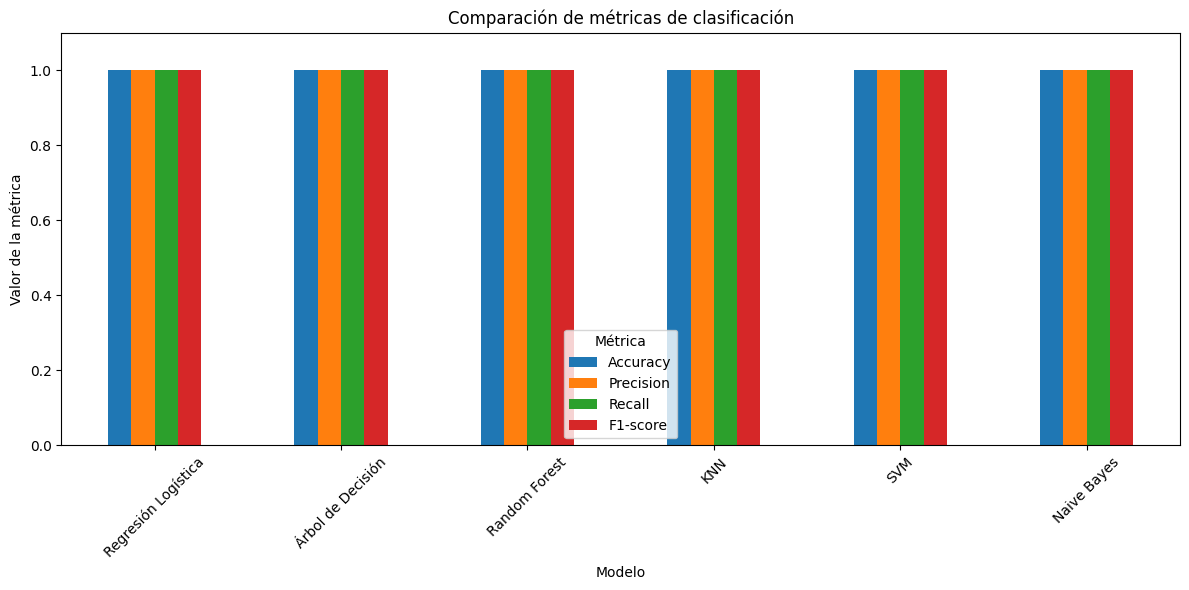

In [17]:
metricas = ["Accuracy", "Precision", "Recall", "F1-score"]

df_resultados.plot(
    x="Modelo",
    y=metricas,
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparación de métricas de clasificación")
plt.xlabel("Modelo")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1.1)
plt.xticks(rotation=45)
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

## 12. Matrices de confusión

La matriz de confusión permite analizar las predicciones realizadas
por cada modelo y distinguir entre verdaderos positivos, verdaderos
negativos, falsos positivos y falsos negativos.

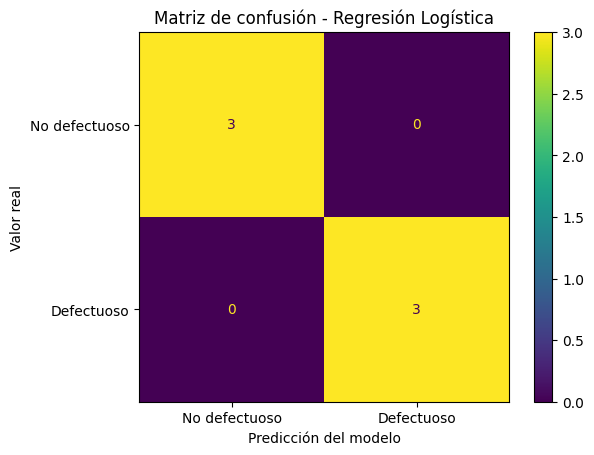

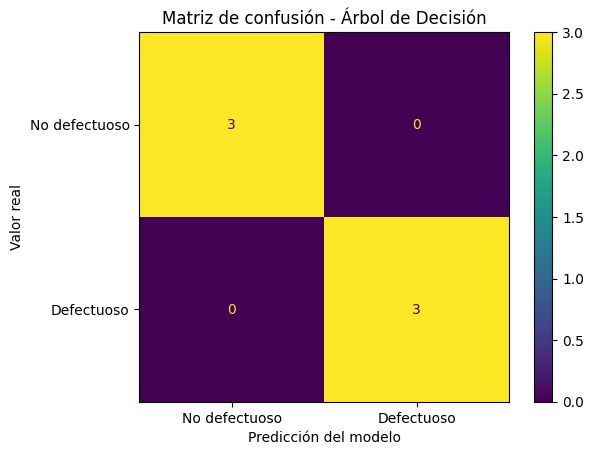

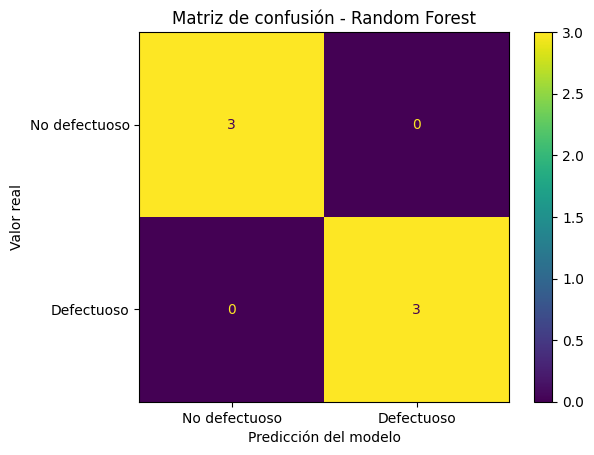

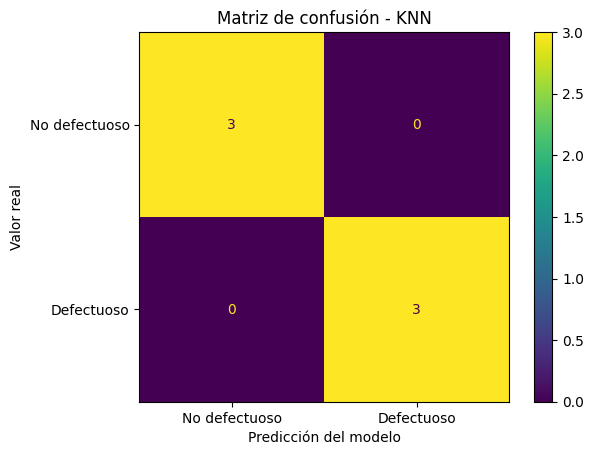

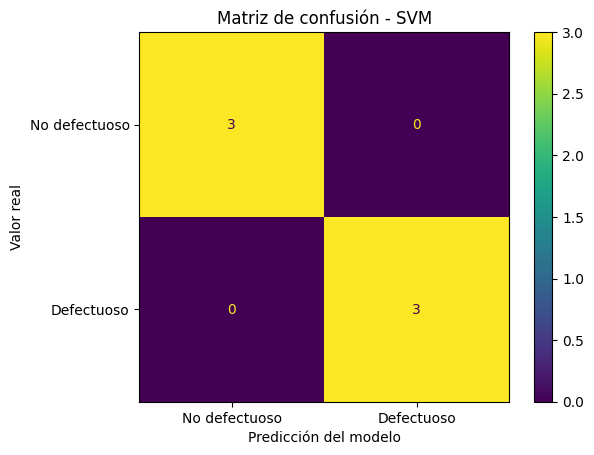

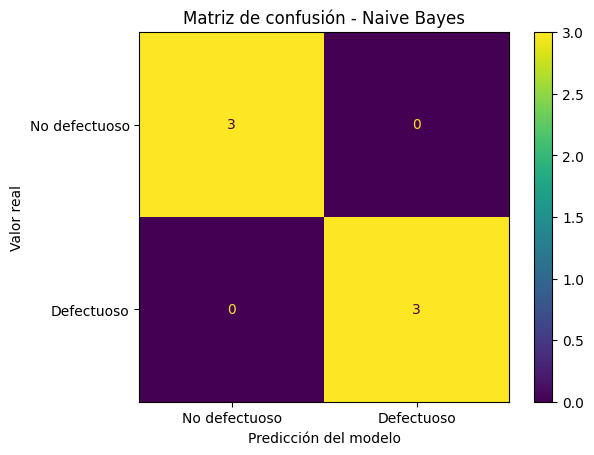

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

for nombre, modelo in modelos.items():

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No defectuoso", "Defectuoso"]
    )

    disp.plot()

    plt.title(f"Matriz de confusión - {nombre}")
    plt.xlabel("Predicción del modelo")
    plt.ylabel("Valor real")
    plt.show()

El modelo dice que el lote está bien, pero realmente es defectuoso.

## 13. Validación cruzada

Se utiliza validación cruzada con cinco particiones para evaluar el
desempeño de los modelos en diferentes particiones del conjunto de
datos.

In [19]:
print("Resultados de validación cruzada:")

for nombre, modelo in modelos.items():

    cv_scores = cross_val_score(
        modelo,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    print(f"\n{nombre}")
    print("Resultados:", cv_scores)
    print("Promedio:", cv_scores.mean())

Resultados de validación cruzada:

Regresión Logística
Resultados: [1. 1. 1. 1. 1.]
Promedio: 1.0

Árbol de Decisión
Resultados: [1. 1. 1. 1. 1.]
Promedio: 1.0

Random Forest
Resultados: [1. 1. 1. 1. 1.]
Promedio: 1.0

KNN
Resultados: [1. 1. 1. 1. 1.]
Promedio: 1.0

SVM
Resultados: [1. 1. 1. 1. 1.]
Promedio: 1.0

Naive Bayes
Resultados: [1. 1. 1. 1. 1.]
Promedio: 1.0


## 14. Tabla comparativa final

Se presenta una comparación de los resultados obtenidos por los seis
algoritmos de clasificación mediante las métricas Accuracy, Precision,
Recall, F1-score y validación cruzada.

In [20]:
# Crear tabla final de resultados
tabla_final = df_resultados.copy()

# Redondear las métricas a dos decimales
columnas_metricas = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Validación cruzada"
]

tabla_final[columnas_metricas] = tabla_final[columnas_metricas].round(2)

display(tabla_final)

,Modelo,Accuracy,Precision,Recall,F1-score,Validación cruzada
0,Regresión Logística,1.0,1.0,1.0,1.0,1.0
1,Árbol de Decisión,1.0,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0,1.0
3,KNN,1.0,1.0,1.0,1.0,1.0
4,SVM,1.0,1.0,1.0,1.0,1.0
5,Naive Bayes,1.0,1.0,1.0,1.0,1.0


## 15. Comparación del Recall

Debido a la importancia de detectar correctamente los lotes
defectuosos, se realiza una comparación específica del Recall
obtenido por cada algoritmo.

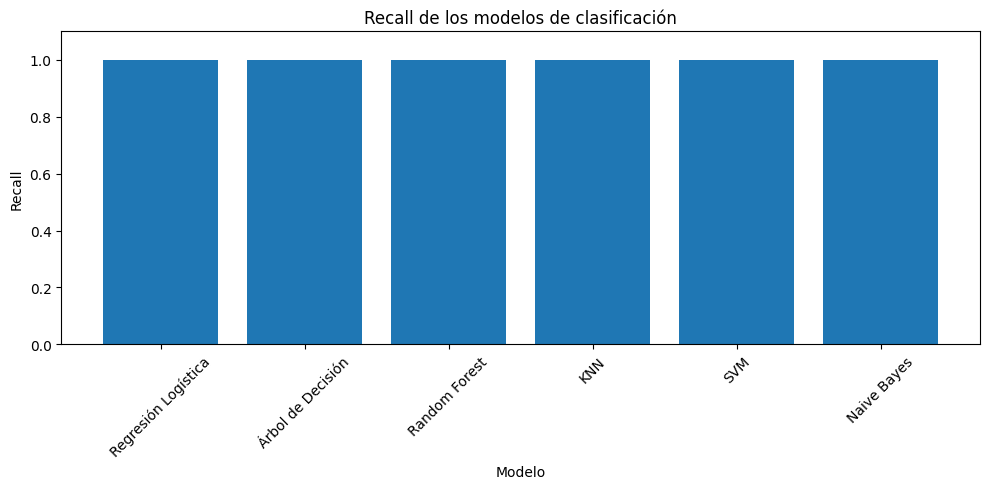

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    tabla_final["Modelo"],
    tabla_final["Recall"]
)

plt.title("Recall de los modelos de clasificación")
plt.xlabel("Modelo")
plt.ylabel("Recall")
plt.ylim(0, 1.1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

La comparación muestra que los seis algoritmos obtuvieron un Recall de 1.00. Este resultado indica que todos los modelos identificaron correctamente los lotes defectuosos presentes en el conjunto de prueba.
El resultado es especialmente favorable para el problema planteado, ya que el principal riesgo corresponde a los falsos negativos, es decir, aquellos casos en los que un lote defectuoso es clasificado como no defectuoso. En el conjunto de prueba no se presentaron falsos negativos para ninguno de los modelos.

# 16. Conclusiones

- Los seis algoritmos implementados presentaron un desempeño de 1.00
en Accuracy, Precision, Recall y F1-score sobre el conjunto de prueba.

- El Recall resulta especialmente relevante para este caso debido a
la importancia de identificar los lotes defectuosos. Los resultados
muestran que ninguno de los modelos presentó falsos negativos en el
conjunto de prueba.

- La validación cruzada con cinco particiones también presentó un
promedio de Accuracy de 1.00 para los modelos evaluados.

- Sin embargo, debido al tamaño reducido del dataset, compuesto por
20 observaciones, estos resultados deben interpretarse con
precaución. Para una aplicación real sería necesario contar con
una mayor cantidad de datos históricos y validar los modelos con
nuevos registros de producción.

- No se identifica un único modelo superior, debido a que los seis
algoritmos presentaron el mismo desempeño en las métricas evaluadas.